# CONCH · GPT R1 · Blur and sharpness departure

Run all cells in order. All acquisition, pixel-feature, axis, scoring and analysis code is contained here. Use the Python3.11 CONCH environment described in section1; the official model requires approved Hugging Face access.

## 1. Data source / acquisition

Download CRC-VAL-HE-7K and all100,000 normalized NCT reference tiles from the pinned public dataset revision; download Stanford from its pinned archive. NCT fits the reference distributions and classifiers. No evaluation images train those references. Pin the official CONCH library at141cc09c7d4ff33d8eda562bd75169b457f71a62; numerical packages are NumPy1.26.4, pandas2.2.2, scipy1.13.1, sklearn1.5.2, Pillow10.4.0, PyTorch2.5.0, torchvision0.20.0, pyarrow16.1.0, statsmodels0.14.2.

**Environment setup before starting the kernel (Linux, Python 3.11):**

Create this shared GPT/Kimi environment before opening the notebook. Keep it separate from the primary CONCH environment, which uses different numerical-library versions.

```bash
python3.11 -m venv .venv-conch-shared
.venv-conch-shared/bin/python -m pip install torch==2.5.0 torchvision==0.20.0 --index-url https://download.pytorch.org/whl/cu124
.venv-conch-shared/bin/python -m pip install numpy==1.26.4 scipy==1.13.1 pandas==2.2.2 scikit-learn==1.5.2 Pillow==10.4.0 pyarrow==16.1.0 scikit-image==0.24.0 statsmodels==0.14.2 opencv-python-headless==4.10.0.84
.venv-conch-shared/bin/python -m pip install matplotlib==3.9.4 timm==0.9.16 transformers==4.40.1 tokenizers==0.19.1 huggingface-hub==0.23.5 ftfy==6.3.1 h5py==3.11.0 open-clip-torch==2.24.0 requests==2.34.2 regex==2026.11.9 safetensors==0.8.0 nbformat==5.10.4 nbclient==0.10.4 nbconvert==7.16.6 ipykernel==6.29.5
.venv-conch-shared/bin/python -m pip install --no-deps "git+https://github.com/mahmoodlab/CONCH.git@141cc09c7d4ff33d8eda562bd75169b457f71a62"
.venv-conch-shared/bin/python -m ipykernel install --user --name conch-gpt-kimi-inline --display-name "CONCH GPT/Kimi"
```

Select **CONCH GPT/Kimi** before Run All. The CUDA 12.4 wheels require a compatible NVIDIA driver; the code also selects CPU if CUDA is unavailable. Authenticate with Hugging Face using an account that can access `MahmoodLab/conch` before the checkpoint-download cell. The `huggingface-cli login` command is provided by the pinned Hub package.

The default input directory is `inputs/` below the notebook working directory. Set `CONCH_INPUTS` before starting the kernel to reuse a shared raw-input directory. The notebook verifies its declared downloaded inputs and runs the calculations shown below, including the stated scoring or eligibility diagnostic. All analysis-specific functions are inline; the installed CONCH package is the pinned public model implementation.

The CONCH model-input transform is explicitly set to 224×224 in the scoring cell. Reference-network weights and transforms are specified in that same cell.


In [1]:
AXIS=5
AXIS_NAME='Blur and sharpness departure'
CRC_SHARDS=['data/CRC_VAL_HE_7K-00000-of-00003-cce1097526b69125.parquet',
 'data/CRC_VAL_HE_7K-00001-of-00003-fbb5de8b1164f4ea.parquet',
 'data/CRC_VAL_HE_7K-00002-of-00003-2009e87e0c48fccf.parquet']

from pathlib import Path
import concurrent.futures,hashlib,io,json,os,shutil,time,zipfile
import requests
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from PIL import Image as PILImage
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,Image
from huggingface_hub import hf_hub_download,hf_hub_url,get_hf_file_metadata
from sklearn.neighbors import NearestNeighbors,NearestCentroid
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

INPUT=Path(os.environ.get('CONCH_INPUTS',Path.cwd()/'inputs'));INPUT.mkdir(parents=True,exist_ok=True)
OUT=Path.cwd()/f'conch-gpt-r1-test-{AXIS:02}-outputs';OUT.mkdir(exist_ok=True)
CLASSES=['ADI','BACK','DEB','LYM','MUC','MUS','NORM','STR','TUM']
CLASS_MAP={'ADI':'ADI','BACK':'BACK','DEB':'DEB','LYM':'LYM','MUC':'MUC','MUS':'MUS','NORM':'NORM','STR':'STR','TUM':'TUM','NCS':'DEB','NOR':'NORM','FCT':'STR','BLD':None}
REVISION='97765ecb14bf11ce7bb8779a1097d187844a67cb'
SOURCE_REVISION='141cc09c7d4ff33d8eda562bd75169b457f71a62'
CHECKPOINT_REVISION='f9ca9f877171a28ade80228fb195ac5d79003357'
SEED=20260714

def sha256(path):
    digest=hashlib.sha256()
    with open(path,'rb') as source:
        for block in iter(lambda:source.read(8<<20),b''):digest.update(block)
    return digest.hexdigest()

def show_figure(figure):
    output=io.BytesIO();figure.savefig(output,format='png',dpi=130,bbox_inches='tight')
    display(Image(data=output.getvalue()));plt.close(figure)

def download(url,destination,expected_sha256=None,expected_bytes=None):
    destination=Path(destination);destination.parent.mkdir(parents=True,exist_ok=True)
    if destination.is_file() and (expected_bytes is None or destination.stat().st_size==expected_bytes) and (expected_sha256 is None or sha256(destination)==expected_sha256):return destination
    temporary=destination.with_name(destination.name+f'.{os.getpid()}.part')
    with requests.get(url,stream=True,timeout=120) as response:
        response.raise_for_status()
        with open(temporary,'wb') as target:
            for block in response.iter_content(8<<20):target.write(block)
    if expected_bytes is not None:assert temporary.stat().st_size==expected_bytes
    if expected_sha256 is not None:assert sha256(temporary)==expected_sha256
    temporary.replace(destination);return destination

def pinned_parquet(filename):
    url=hf_hub_url('1aurent/NCT-CRC-HE',filename,repo_type='dataset',revision=REVISION)
    metadata=get_hf_file_metadata(url)
    digest=metadata.etag.strip('"')
    assert len(digest)==64,'Expected a large-file SHA-256 identity'
    return download(url,INPUT/'hf_parquet'/filename,digest,metadata.size)

stanford_record=dict(url='https://huggingface.co/datasets/Path2AI/STARC-9/resolve/2c4b716dc5370c9628162ceb9190f0b92eaafd3c/Validation_data/STANFORD-CRC-HE-VAL-SMALL-NORMALIZED.zip',sha256='088281de09bfe4d57b4a8e356a99cdb9b002a08a0ff7c44910aee0b4de81d3f3',bytes=2149005637)
stanford_archive=download(stanford_record['url'],INPUT/'STANFORD-CRC-HE-VAL-SMALL-NORMALIZED.zip',stanford_record['sha256'],stanford_record['bytes'])
with concurrent.futures.ThreadPoolExecutor(max_workers=3) as pool:
    crc_paths=list(pool.map(pinned_parquet,CRC_SHARDS))
display(pd.DataFrame([dict(source='CRC-VAL',url=hf_hub_url('1aurent/NCT-CRC-HE',name,repo_type='dataset',revision=REVISION),path=str(path),sha256=sha256(path)) for name,path in zip(CRC_SHARDS,crc_paths)]+[dict(source='Stanford',url=stanford_record['url'],path=str(stanford_archive),sha256=stanford_record['sha256'])]))

CLASS_MAP.update({'NCS':None,'FCT':None,'BLD':None})

from huggingface_hub import list_repo_files
nct_filenames=sorted(name for name in list_repo_files('1aurent/NCT-CRC-HE',repo_type='dataset',revision=REVISION) if name.startswith('data/NCT_CRC_HE_100K-') and name.endswith('.parquet'))
assert len(nct_filenames)==31
with concurrent.futures.ThreadPoolExecutor(max_workers=4) as pool:nct_paths=list(pool.map(pinned_parquet,nct_filenames))
print('Full NCT reference shards verified:',len(nct_paths))


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,source,url,path,sha256
0,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,/ewsc/yektefai/spectra_runs/conch_nonprimary_r...,fc4aa78c380802f27e59a70b2f2877dc3d2b82ddc2b800...
1,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,/ewsc/yektefai/spectra_runs/conch_nonprimary_r...,d607ebd6b861e3aec2ae2d457993f42222393abb9bdd99...
2,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,/ewsc/yektefai/spectra_runs/conch_nonprimary_r...,d733e143f0c984d24262d7b98d30669a885e7a6e3fcb46...
3,Stanford,https://huggingface.co/datasets/Path2AI/STARC-...,/ewsc/yektefai/spectra_runs/conch_nonprimary_r...,088281de09bfe4d57b4a8e356a99cdb9b002a08a0ff7c4...


Full NCT reference shards verified: 31


In [2]:
def save_image(raw,source,source_key,label):
    encoded_hash=hashlib.sha256(raw).hexdigest()
    path=INPUT/'raw_images'/source/(encoded_hash+'.image')
    path.parent.mkdir(parents=True,exist_ok=True)
    if not path.exists() or sha256(path)!=encoded_hash:
        temporary=path.with_name(path.name+f'.{os.getpid()}.part');temporary.write_bytes(raw);temporary.replace(path)
    return dict(cohort=source,source_key=source_key,tile_id=encoded_hash,path=str(path),raw_label=label,encoded_sha256=encoded_hash)

crc_rows=[]
for source_name,path in zip(CRC_SHARDS,crc_paths):
    parquet=pq.ParquetFile(path)
    for group in range(parquet.num_row_groups):
        for index,example in enumerate(parquet.read_row_group(group,columns=['image','label']).to_pylist()):
            image=example['image'];label=CLASSES[int(example['label'])]
            source_key=f'{source_name}:{group}:{index}:{image.get("path","")}'
            crc_rows.append(save_image(image['bytes'],'CRC',source_key,label))
stanford_rows=[]
with zipfile.ZipFile(stanford_archive) as archive:
    for member in sorted(archive.namelist()):
        if not member.lower().endswith(('.png','.tif','.tiff','.jpg','.jpeg')):continue
        label=Path(member).parent.name
        assert label in CLASS_MAP,label
        stanford_rows.append(save_image(archive.read(member),'Stanford',member,label))


reference_rows=[]
for filename,path in zip(nct_filenames,nct_paths):
    parquet=pq.ParquetFile(path)
    for group in range(parquet.num_row_groups):
        for index,example in enumerate(parquet.read_row_group(group,columns=['image','label']).to_pylist()):
            label=CLASSES[int(example['label'])];image=example['image']
            key=f'NCT-CRC-HE-100K/{label}/{Path(image.get("path") or str(index)).name}'
            reference_rows.append(save_image(image['bytes'],'NCT-reference',key,label))
raw_index=pd.DataFrame(crc_rows+stanford_rows+reference_rows)
assert len(reference_rows)==100000
raw_index['label']=raw_index.raw_label.map(CLASS_MAP)
raw_index['tile_id']=[hashlib.sha256(({'CRC':'crc_val_7k','Stanford':'stanford_crc_val_small','NCT-reference':'nct_crc_100k'}.get(row.cohort,row.cohort)+'\0'+(f'CRC-VAL-HE-7K/{row.raw_label}/'+row.source_key.rsplit(':',1)[-1] if row.cohort=='CRC' else row.source_key)).encode()).hexdigest()[:24] for row in raw_index.itertuples(index=False)]
display(raw_index.groupby(['cohort','raw_label']).size().unstack(fill_value=0))


raw_label,ADI,BACK,BLD,DEB,FCT,LYM,MUC,MUS,NCS,NOR,NORM,STR,TUM
cohort,,,,,,,,,,,,,
CRC,1338,847,0,339,0,634,1035,592,0,0,741,421,1233
NCT-reference,10407,10566,0,11512,0,11557,8896,13536,0,0,8763,10446,14317
Stanford,2000,0,2000,0,2000,2000,2000,2000,2000,2000,0,0,2000


## 2. Data processing

Calculate color histograms, optical density, local binary patterns, gradient orientation, frequency bands, multiscale contrast, focus and tissue fraction directly from image pixels. Stanford uses only the exact common classes ADI, LYM, MUC, MUS, NOR→NORM and TUM; no mapping is imposed on blood, necrosis or fibrous connective tissue.

In [3]:
def entropy(x: np.ndarray, bins: int = 64) -> float:
    h = np.histogram(x, bins=bins, range=(0, 1))[0].astype(float)
    p = h[h > 0] / h.sum()
    return float(-(p * np.log2(p)).sum())

def one(path_text: str) -> dict[str, float | str]:
    path = Path(path_text)
    with PILImage.open(path) as im:
        rgb = np.asarray(im.convert("RGB"), dtype=np.float32) / 255.0
        hsv = np.asarray(im.convert("HSV"), dtype=np.float32) / 255.0
    gray = rgb @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    sat = hsv[..., 1]
    val = hsv[..., 2]
    tissue = (sat > 0.08) & (val < 0.92)
    padded = np.pad(gray, 1, mode="reflect")
    gx = (
        -padded[:-2, :-2] + padded[:-2, 2:]
        - 2 * padded[1:-1, :-2] + 2 * padded[1:-1, 2:]
        - padded[2:, :-2] + padded[2:, 2:]
    ) / 8.0
    gy = (
        -padded[:-2, :-2] - 2 * padded[:-2, 1:-1] - padded[:-2, 2:]
        + padded[2:, :-2] + 2 * padded[2:, 1:-1] + padded[2:, 2:]
    ) / 8.0
    mag = np.hypot(gx, gy)
    angle = (np.arctan2(gy, gx) + np.pi) % np.pi
    lap = (
        padded[:-2, 1:-1] + padded[2:, 1:-1] + padded[1:-1, :-2]
        + padded[1:-1, 2:] - 4 * gray
    )
    od = -np.log(np.clip(rgb, 1 / 255.0, 1.0))

    center = gray[1:-1, 1:-1]
    neighbors = [
        gray[:-2, :-2], gray[:-2, 1:-1], gray[:-2, 2:], gray[1:-1, 2:],
        gray[2:, 2:], gray[2:, 1:-1], gray[2:, :-2], gray[1:-1, :-2],
    ]
    code = np.zeros_like(center, dtype=np.uint8)
    for bit, n in enumerate(neighbors):
        code |= ((n >= center).astype(np.uint8) << bit)

    f = np.fft.fftshift(np.fft.fft2(gray - gray.mean()))
    power = np.abs(f) ** 2
    yy, xx = np.indices(gray.shape)
    rr = np.hypot(yy - (gray.shape[0] - 1) / 2, xx - (gray.shape[1] - 1) / 2)
    rr /= max(gray.shape) / 2

    dh = np.asarray(PILImage.fromarray(np.uint8(gray * 255)).resize((9, 8), PILImage.Resampling.BILINEAR))
    dhash = sum(int(bit) << i for i, bit in enumerate((dh[:, 1:] >= dh[:, :-1]).ravel()))
    row: dict[str, float | str] = {"path": path_text, "tile_id": path.stem, "dhash64": f"{dhash:016x}"}
    for c, name in enumerate(("r", "g", "b")):
        v = rgb[..., c]
        row[f"{name}_mean"] = float(v.mean())
        row[f"{name}_std"] = float(v.std())
        row[f"{name}_q10"] = float(np.quantile(v, 0.10))
        row[f"{name}_q50"] = float(np.quantile(v, 0.50))
        row[f"{name}_q90"] = float(np.quantile(v, 0.90))
        hist = np.histogram(v, bins=16, range=(0, 1), density=False)[0] / v.size
        for i, z in enumerate(hist):
            row[f"{name}_hist_{i:02d}"] = float(z)
    row.update({
        "gray_mean": float(gray.mean()), "gray_std": float(gray.std()),
        "gray_entropy": entropy(gray), "sat_mean": float(sat.mean()),
        "sat_std": float(sat.std()), "val_mean": float(val.mean()),
        "tissue_fraction": float(tissue.mean()), "white_fraction": float((val > 0.95).mean()),
        "focus_laplacian_var": float(lap.var()), "tenengrad_mean": float((mag * mag).mean()),
        "edge_fraction": float((mag > 0.08).mean()), "od_mean": float(od.mean()),
        "od_std": float(od.std()), "od_r_mean": float(od[..., 0].mean()),
        "od_g_mean": float(od[..., 1].mean()), "od_b_mean": float(od[..., 2].mean()),
    })
    lbp = np.histogram(code, bins=16, range=(0, 256))[0] / code.size
    for i, z in enumerate(lbp):
        row[f"lbp_{i:02d}"] = float(z)
    orient = np.histogram(angle, bins=8, range=(0, np.pi), weights=mag)[0]
    orient /= orient.sum() + 1e-12
    for i, z in enumerate(orient):
        row[f"orient_{i:02d}"] = float(z)
    for i, (lo, hi) in enumerate(((0.02, 0.08), (0.08, 0.20), (0.20, 0.45), (0.45, 1.0))):
        mask = (rr >= lo) & (rr < hi)
        row[f"fft_band_{i}"] = float(np.log1p(power[mask].mean()))
    gray_image = PILImage.fromarray(np.uint8(np.clip(gray * 255, 0, 255)))
    for sigma in (1, 2, 4, 8):
        smooth = np.asarray(gray_image.filter(ImageFilter.GaussianBlur(radius=sigma)), dtype=np.float32) / 255.0
        row[f"contrast_s{sigma}"] = float((gray - smooth).std())
    return row

from PIL import ImageFilter
def compute_row(row):
    features=one(row.path)
    features.update(tile_id=row.tile_id,cohort=row.cohort)
    # Compression is a separate nuisance measurement, excluded from the texture axis.
    with PILImage.open(row.path) as image:
        gray=np.asarray(image.convert('L'),dtype=float)/255
    dx=np.abs(np.diff(gray,axis=1));dy=np.abs(np.diff(gray,axis=0))
    boundary=dx[:,7::8].mean()+dy[7::8,:].mean()
    interior=np.delete(dx,np.arange(7,dx.shape[1],8),axis=1).mean()+np.delete(dy,np.arange(7,dy.shape[0],8),axis=0).mean()
    features['jpeg_blockiness']=boundary/(interior+1e-12)
    return features

with concurrent.futures.ThreadPoolExecutor(max_workers=8) as pool:
    features=pd.DataFrame(pool.map(compute_row,raw_index.itertuples(index=False)))
features=features.drop(columns='path')
data=raw_index.merge(features,on=['cohort','tile_id'],validate='one_to_one')
data.to_parquet(OUT/'image_features.parquet',index=False)
print('Fresh pixel feature rows:',len(data))


Fresh pixel feature rows: 125180


## 3. Axis definition and level construction

Fit median/IQR scaling and64 texture prototypes using the deterministic80% NCT split. Color/stain32-prototype and quality16-prototype distances are controls. The texture axis is minimum root-mean-square standardized distance to a prototype. Freeze quintiles within each complete target cohort, then deduplicate and require50 examples of a class in every level for evaluation. Exclude target dHash neighbors within Hamming distance4 of NCT.

In [4]:
def deterministic_fit_mask(ids: pd.Series) -> np.ndarray:
    return np.array([int(hashlib.sha256(x.encode()).hexdigest()[:8], 16) % 5 != 0 for x in ids], dtype=bool)

def robust_fit(x: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    median = np.nanmedian(x, axis=0)
    q25, q75 = np.nanquantile(x, [0.25, 0.75], axis=0)
    scale = q75 - q25
    scale[scale < 1e-8] = 1.0
    return median, scale

def transform(x: np.ndarray, median: np.ndarray, scale: np.ndarray) -> np.ndarray:
    return np.nan_to_num((x - median) / scale, nan=0.0, posinf=20.0, neginf=-20.0).clip(-20, 20)

def nearest_distance(x: np.ndarray, centers: np.ndarray) -> np.ndarray:
    out = np.empty(len(x), dtype=np.float32)
    for start in range(0, len(x), 4096):
        block = x[start:start + 4096]
        d2 = ((block[:, None, :] - centers[None, :, :]) ** 2).mean(axis=2)
        out[start:start + len(block)] = np.sqrt(d2.min(axis=1))
    return out

def ecdf_percentile(values: np.ndarray, reference: np.ndarray) -> np.ndarray:
    ordered = np.sort(reference)
    return np.searchsorted(ordered, values, side="right") / len(ordered)

def assign_levels(values: np.ndarray) -> tuple[np.ndarray, list[float]]:
    thresholds = np.quantile(values, [0.2, 0.4, 0.6, 0.8]).tolist()
    return np.digitize(values, thresholds, right=True) + 1, thresholds

class BKTree:
    def __init__(self):
        self.root = None

    @staticmethod
    def dist(a: int, b: int) -> int:
        return (a ^ b).bit_count()

    def add(self, value: int, tile_id: str) -> None:
        node = (value, [tile_id], {})
        if self.root is None:
            self.root = node
            return
        current = self.root
        while True:
            d = self.dist(value, current[0])
            if d == 0:
                current[1].append(tile_id)
                return
            if d not in current[2]:
                current[2][d] = node
                return
            current = current[2][d]

    def query(self, value: int, radius: int = 4):
        if self.root is None:
            return []
        out, stack = [], [self.root]
        while stack:
            node = stack.pop()
            d = self.dist(value, node[0])
            if d <= radius:
                out.extend((tile_id, d) for tile_id in node[1])
            stack.extend(child for edge, child in node[2].items() if d - radius <= edge <= d + radius)
        return out


from sklearn.cluster import MiniBatchKMeans
reference_data=data[data.cohort=='NCT-reference'].copy()
morph_cols=[column for column in data if column.startswith(('lbp_','orient_','fft_band_','contrast_s'))]+['gray_std','gray_entropy']
color_cols=[column for column in data if column.startswith(('r_hist_','g_hist_','b_hist_'))]+['r_mean','g_mean','b_mean','sat_mean','sat_std','od_mean','od_std']
quality_cols=['focus_laplacian_var','tenengrad_mean','edge_fraction','tissue_fraction','white_fraction']
fit_mask=deterministic_fit_mask(reference_data.tile_id)
targets=data[data.cohort!='NCT-reference'].copy()
models={}
for name,columns,number in [('morphology_texture',morph_cols,64),('color_stain',color_cols,32),('quality',quality_cols,16)]:
    raw=reference_data[columns].to_numpy(float)
    median,scale=robust_fit(raw[fit_mask]);z=transform(raw,median,scale)
    clustering=MiniBatchKMeans(n_clusters=number,random_state=20260714,batch_size=4096,n_init=3,max_iter=200).fit(z[fit_mask])
    ref_distance=nearest_distance(z,clustering.cluster_centers_)
    targets[name+'_distance']=nearest_distance(transform(targets[columns].to_numpy(float),median,scale),clustering.cluster_centers_)
    if name=='morphology_texture':targets['reference_percentile']=ecdf_percentile(targets[name+'_distance'],ref_distance[~fit_mask])
    models[name]=dict(columns=columns,median=median.tolist(),scale=scale.tolist(),centers=clustering.cluster_centers_.tolist())
targets['distance']=targets.morphology_texture_distance
targets['stain_distance']=targets.color_stain_distance
targets['texture_distance']=targets.morphology_texture_distance
targets['composition_distance']=targets.quality_distance
targets['laplacian_variance']=targets.focus_laplacian_var
targets['hf_power_ratio']=targets.fft_band_3
targets['level']=0
for cohort,group in targets.groupby('cohort'):
    targets.loc[group.index,'level'],thresholds=assign_levels(group.distance.to_numpy())
targets['level']=targets.level.astype(int)
(OUT/'axis_parameters.json').write_text(json.dumps(models,indent=2))
targets.to_parquet(OUT/'prospective_levels.parquet',index=False)
display(targets.groupby(['cohort','level']).agg(images=('tile_id','size'),distance=('distance','median'),color_distance=('stain_distance','median'),quality_distance=('quality_distance','median'),focus=('laplacian_variance','median'),tissue=('tissue_fraction','mean')))

# Remove exact duplicates within each cohort and dHash neighbors of the reference.
targets=targets.sort_values('tile_id').drop_duplicates(['cohort','encoded_sha256'])
tree=BKTree()
for row in reference_data.itertuples(index=False):tree.add(int(row.dhash64,16),row.tile_id)
near=[]
for row in targets.itertuples(index=False):
    hits=tree.query(int(row.dhash64,16),radius=4)
    if hits:
        best=min(hits,key=lambda value:value[1])
        near.append(dict(cohort=row.cohort,tile_id=row.tile_id,reference_tile_id=best[0],hamming_distance=best[1]))
near=pd.DataFrame(near,columns=['cohort','tile_id','reference_tile_id','hamming_distance'])
near.to_csv(OUT/'near_duplicate_exclusions.csv',index=False)
targets=targets[~targets.tile_id.isin(near.tile_id)].copy()
counts=targets[targets.label.notna()].groupby(['cohort','label','level']).size().unstack(fill_value=0).reindex(columns=[1,2,3,4,5],fill_value=0)
eligible={cohort:sorted(group.index.get_level_values('label')[group.min(axis=1)>=50]) for cohort,group in counts.groupby(level='cohort')}
evaluation=targets[[row.label in eligible.get(row.cohort,[]) for row in targets.itertuples(index=False)]].copy()
display(counts);display(pd.DataFrame([dict(cohort=cohort,eligible_classes=classes) for cohort,classes in eligible.items()]))
counts.to_csv(OUT/'class_level_counts.csv')


images  distance  color_distance  quality_distance     focus  \
cohort   level                                                                 
CRC      1        1436  0.239098        0.489264          0.205805  0.010386   
         2        1436  0.315358        0.560181          0.224805  0.010760   
         3        1436  0.386833        0.683533          0.238070  0.011749   
         4        1436  0.475549        0.898634          0.259097  0.009896   
         5        1436  0.616920        1.215056          0.277593  0.007416   
Stanford 1        3600  0.304656        0.842215          0.202133  0.007147   
         2        3600  0.386895        0.982897          0.232147  0.006302   
         3        3600  0.464060        1.108697          0.260771  0.005885   
         4        3600  0.563504        1.173719          0.278090  0.005688   
         5        3600  0.732217        1.130215          0.289641  0.006051   

                  tissue  
cohort   level            
CRC      1      0.836256  
         2      0.824266  
         3      0.823398  
         4      0.722483  
         5      0.538941  
Stanford 1      0.886574  
         2      0.853612  
         3      0.820958  
         4      0.749581  
         5      0.690026

level             1    2    3    4    5
cohort   label                         
CRC      ADI     23   63  153  363  733
         BACK   129  172  233  225   69
         DEB    149  133   49    8    0
         LYM    174  113  105  148   94
         MUC     86  231  346  279   92
         MUS     36   63  107  128  258
         NORM   344  192  132   57   16
         STR     64   79   87  100   91
         TUM    427  383  222  122   77
Stanford ADI     14   77  273  739  896
         LYM    218  569  644  447  120
         MUC    270  337  384  401  563
         MUS    263  265  282  443  746
         NORM   741  580  400  242   37
         TUM    594  627  473  239   66

,cohort,eligible_classes
0,CRC,"[BACK, LYM, MUC, STR, TUM]"
1,Stanford,"[LYM, MUC, MUS, TUM]"


## 4. Model results or released scores

Run CONCH zero-shot inference using the official checkpoint and prompt ensemble. No CONCH fine-tuning occurs. Fit a standardized handcrafted logistic classifier and an ImageNet MobileNet nearest-centroid reference on NCT images only, and evaluate identical target images.

In [5]:
import torch
import torchvision.models as models
from torchvision import transforms
from conch.open_clip_custom import create_model_from_pretrained
from conch.downstream.zeroshot_path import zero_shot_classifier
torch.set_num_threads(4)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
checkpoint=INPUT/'conch_checkpoint/pytorch_model.bin'
if not checkpoint.exists() or sha256(checkpoint)!='40a9644b9ba0e83a74576e0a5e5f7313599fa9c9cdaf3c20f8a3e271b0e9ae7c':
    checkpoint=Path(hf_hub_download('MahmoodLab/conch','pytorch_model.bin',revision=CHECKPOINT_REVISION))
assert sha256(checkpoint)=='40a9644b9ba0e83a74576e0a5e5f7313599fa9c9cdaf3c20f8a3e271b0e9ae7c'
prompt_path=download(f'https://raw.githubusercontent.com/mahmoodlab/CONCH/{SOURCE_REVISION}/prompts/crc100k_prompts_all_per_class.json',INPUT/'crc100k_prompts_all_per_class.json','5cac7ab39a593e10d053647842401eae00b94351bd33c5edcad29b17757343e2')
prompt=json.loads(prompt_path.read_text())['0']
conch,preprocess=create_model_from_pretrained('conch_ViT-B-16',str(checkpoint),device=DEVICE,force_image_size=224)
conch.eval()
text_weights=zero_shot_classifier(conch,[prompt['classnames'][name] for name in CLASSES],prompt['templates'],device=DEVICE)

@torch.inference_mode()
def image_embeddings(frame,model,preprocess,is_conch=False):
    values=[]
    for start in range(0,len(frame),64):
        batch=[]
        for path in frame.path.iloc[start:start+64]:
            with PILImage.open(path) as image:batch.append(preprocess(image.convert('RGB')))
        tensor=torch.stack(batch).to(DEVICE)
        encoded=model.encode_image(tensor,proj_contrast=True,normalize=True) if is_conch else model(tensor)
        values.append(encoded.cpu().numpy())
    return np.concatenate(values)

conch_embedding=image_embeddings(evaluation,conch,preprocess,True)
logits=float(conch.logit_scale.exp().detach().cpu())*conch_embedding@text_weights.detach().cpu().numpy()
predictions=evaluation[['cohort','tile_id','label','level','distance','stain_distance','texture_distance','composition_distance','laplacian_variance','hf_power_ratio','jpeg_blockiness','tissue_fraction']].copy()
predictions['CONCH']=np.asarray(CLASSES)[logits.argmax(axis=1)]
np.save(OUT/'conch_logits.npy',logits)
del conch;torch.cuda.empty_cache()


# Fit the two fixed references on NCT only.
excluded={'path','tile_id','source_key','encoded_sha256','cohort','raw_label','label','dhash64'}
columns=[column for column in reference_data if column not in excluded and pd.api.types.is_numeric_dtype(reference_data[column]) and column!='jpeg_blockiness']
handcrafted=make_pipeline(StandardScaler(),LogisticRegression(C=1,solver='lbfgs',max_iter=1000,class_weight='balanced',random_state=20260714))
handcrafted.fit(reference_data[columns],reference_data.label)
predictions['Handcrafted logistic']=handcrafted.predict(evaluation[columns])
weight=download('https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth',INPUT/'mobilenet_v3_small-047dcff4.pth','047dcff4addef86ea5bc2eff13c9614dc11f47ab1160d0a71a25e7db994f4e1f',10306551)
encoder=models.mobilenet_v3_small(weights=None);encoder.load_state_dict(torch.load(weight,map_location='cpu',weights_only=True));encoder.classifier=torch.nn.Identity();encoder=encoder.to(DEVICE).eval()
pre_mobile=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1.transforms()
train_embedding=image_embeddings(reference_data,encoder,pre_mobile).astype(float)
test_embedding=image_embeddings(evaluation,encoder,pre_mobile).astype(float)
train_embedding/=np.linalg.norm(train_embedding,axis=1,keepdims=True).clip(1e-12)
test_embedding/=np.linalg.norm(test_embedding,axis=1,keepdims=True).clip(1e-12)
centroids=np.stack([train_embedding[reference_data.label.to_numpy()==label].mean(axis=0) for label in CLASSES])
centroids/=np.linalg.norm(centroids,axis=1,keepdims=True).clip(1e-12)
predictions['MobileNet centroid']=np.asarray(CLASSES)[(test_embedding@centroids.T).argmax(axis=1)]
predictions.to_parquet(OUT/'per_image_predictions.parquet',index=False)
METHODS=['CONCH','Handcrafted logistic','MobileNet centroid']
display(predictions.groupby('cohort').size().rename('Scored images'))


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/conch/open_clip_custom/factory.py:18: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental featur

cohort
CRC         4148
Stanford    7951
Name: Scored images, dtype: int64

## 5. Curves and controls

Calculate class-balanced curves, paired tile bootstrap intervals, within-class recalls, adjusted correctness trends and the frozen matching analysis. Matching compares the extremes within tissue class and tertiles of stain distance, focus and tissue fraction.

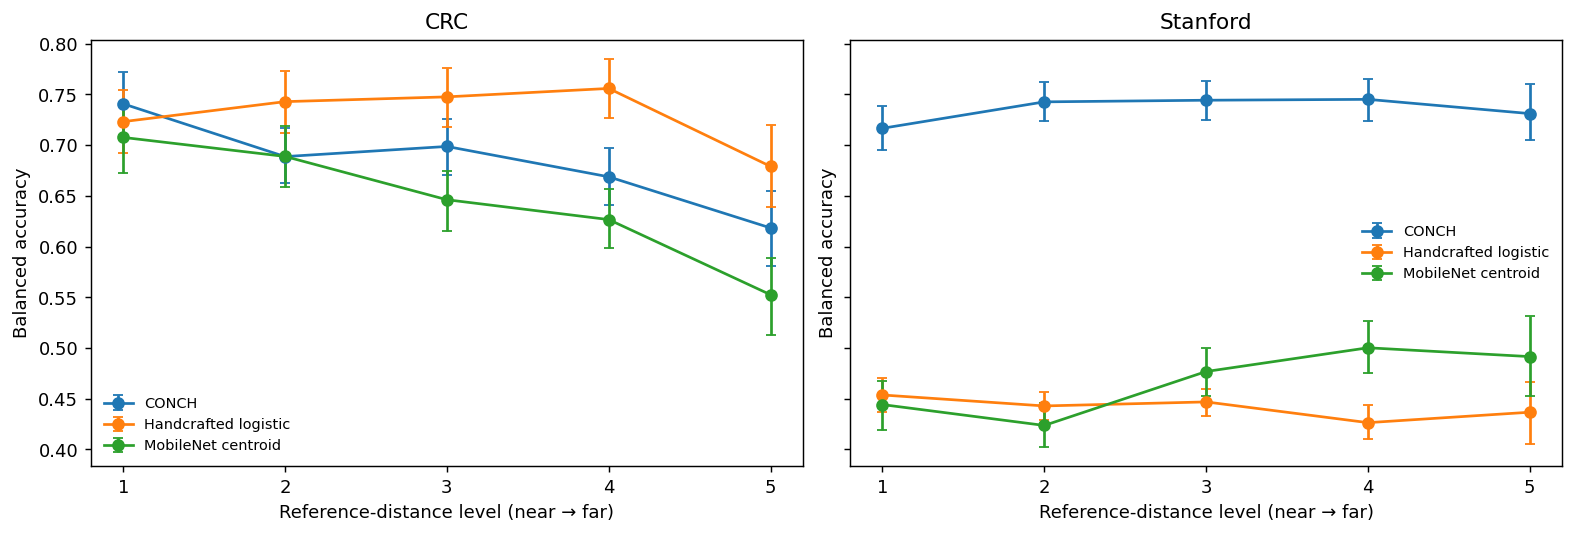

,cohort,method,drop,low,high,classes
0,CRC,CONCH,0.122381,0.074656,0.168995,5
1,CRC,Handcrafted logistic,0.044132,-0.005061,0.095944,5
2,CRC,MobileNet centroid,0.155139,0.102263,0.206050,5
3,CRC,CONCH minus Handcrafted logistic,0.078250,0.010680,0.141862,5
4,CRC,CONCH minus MobileNet centroid,-0.032758,-0.104108,0.035665,5
5,Stanford,CONCH,-0.014493,-0.051264,0.020291,4
6,Stanford,Handcrafted logistic,0.016996,-0.018809,0.051154,4
7,Stanford,MobileNet centroid,-0.047320,-0.092627,-0.004861,4
8,Stanford,CONCH minus Handcrafted logistic,-0.031489,-0.078345,0.015001,4
9,Stanford,CONCH minus MobileNet centroid,0.032827,-0.019299,0.086744,4


,cohort,model,term,beta,odds_ratio,low,high,p
0,CRC,Class adjusted,ordered_level,-0.308045,0.734882,0.675697,0.799251,6.452250e-13
1,CRC,Fully adjusted,ordered_level,-0.236387,0.789475,0.719686,0.866032,5.561402e-07
2,CRC,Fully adjusted,stain_distance,0.057452,1.059135,0.940550,1.192670,3.429729e-01
3,CRC,Fully adjusted,log_sharpness,0.565204,1.759807,0.749495,4.132010,1.943440e-01
4,CRC,Fully adjusted,hf_power_ratio,0.099385,1.104492,0.421272,2.895757,8.398424e-01
5,CRC,Fully adjusted,jpeg_blockiness,0.010004,1.010054,0.945445,1.079079,7.667629e-01
6,CRC,Fully adjusted,tissue_fraction,0.386520,1.471850,1.285408,1.685336,2.229335e-08
7,Stanford,Class adjusted,ordered_level,0.135670,1.145304,1.076044,1.219021,2.018690e-05
8,Stanford,Fully adjusted,ordered_level,0.099157,1.104239,1.031256,1.182387,4.480947e-03
9,Stanford,Fully adjusted,stain_distance,0.041432,1.042303,0.910478,1.193214,5.481347e-01


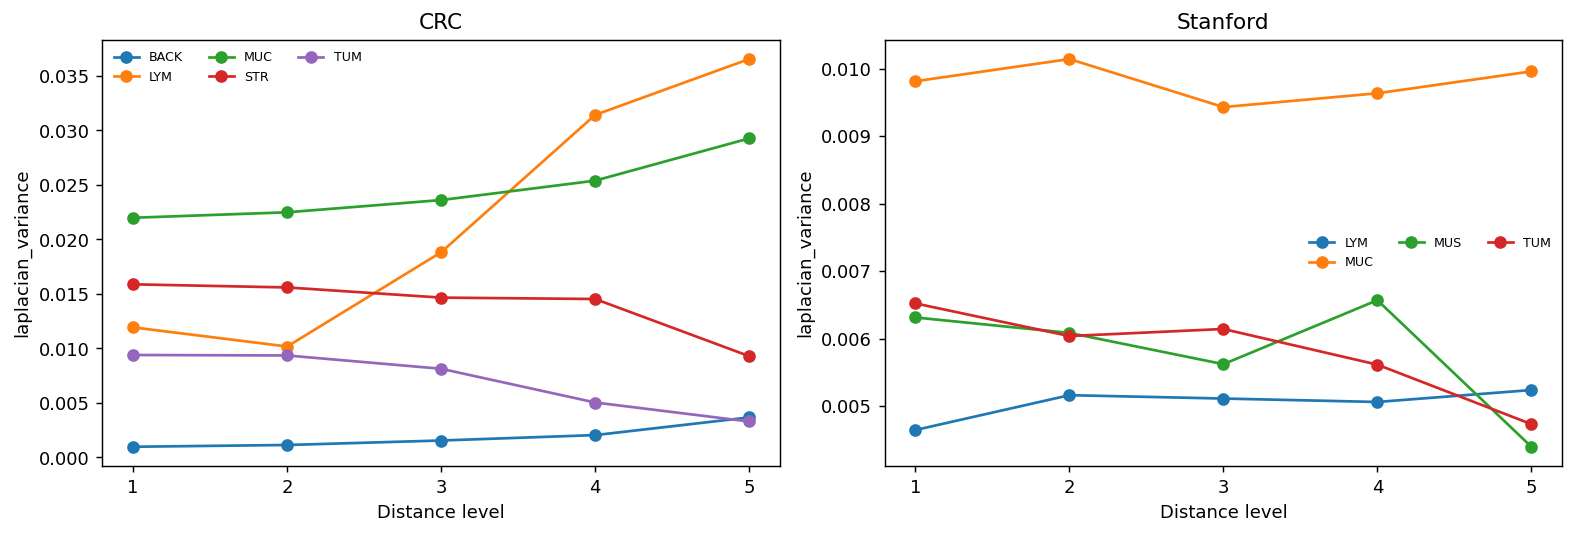

level                  1         2         3         4         5
cohort   label                                                  
CRC      BACK   0.426357  0.377907  0.472103  0.453333  0.623188
         LYM    1.000000  1.000000  1.000000  1.000000  0.968085
         MUC    0.976744  0.991342  0.976879  0.992832  0.967391
         STR    0.500000  0.367089  0.436782  0.480000  0.351648
         TUM    0.800937  0.707572  0.608108  0.418033  0.181818
Stanford LYM    0.894495  0.978910  0.978261  0.964206  0.950000
         MUC    0.911111  0.922849  0.916667  0.917706  0.948490
         MUS    0.577947  0.581132  0.670213  0.722348  0.798928
         TUM    0.483165  0.488038  0.412262  0.376569  0.227273

In [6]:
import statsmodels.api as sm
from scipy.stats import spearmanr
from sklearn.metrics import f1_score
BOOTSTRAPS=2000

def balanced_accuracy(frame,method):
    return float(np.mean([(group[method]==group.label).mean() for _,group in frame.groupby('label')]))

def bootstrap_bacc(frame,methods,rng):
    # The same class-stratified resamples are used for every model comparison.
    sums=np.zeros((BOOTSTRAPS,len(methods)))
    classes=sorted(frame.label.unique())
    for label in classes:
        group=frame[frame.label==label]
        correct=np.column_stack([(group[method]==group.label).to_numpy(dtype=float) for method in methods])
        for start in range(0,BOOTSTRAPS,100):
            stop=min(start+100,BOOTSTRAPS)
            sample=rng.integers(0,len(group),(stop-start,len(group)))
            sums[start:stop]+=correct[sample].mean(axis=1)
    return sums/len(classes)

rng=np.random.default_rng(SEED);curve_rows=[];effect_rows=[];within=[];regressions=[]
for cohort,frame in predictions.groupby('cohort'):
    # Use the same classes at both extremes for the paired endpoint.
    low=frame[frame.level==1];high=frame[frame.level==5]
    common=set(low.label)&set(high.label)
    low=low[low.label.isin(common)];high=high[high.label.isin(common)]
    drops=bootstrap_bacc(low,METHODS,rng)-bootstrap_bacc(high,METHODS,rng)
    for index,method in enumerate(METHODS):
        lo,hi=np.quantile(drops[:,index],[.025,.975])
        effect_rows.append(dict(cohort=cohort,method=method,drop=balanced_accuracy(low,method)-balanced_accuracy(high,method),low=lo,high=hi,classes=len(common)))
    for index,method in enumerate(METHODS[1:],1):
        difference=drops[:,0]-drops[:,index];lo,hi=np.quantile(difference,[.025,.975])
        effect_rows.append(dict(cohort=cohort,method='CONCH minus '+method,drop=(balanced_accuracy(low,'CONCH')-balanced_accuracy(high,'CONCH'))-(balanced_accuracy(low,method)-balanced_accuracy(high,method)),low=lo,high=hi,classes=len(common)))
    for level,group in frame.groupby('level'):
        boot=bootstrap_bacc(group,METHODS,rng)
        for index,method in enumerate(METHODS):
            lo,hi=np.quantile(boot[:,index],[.025,.975])
            curve_rows.append(dict(cohort=cohort,method=method,level=level,n=len(group),distance=group.distance.median(),balanced_accuracy=balanced_accuracy(group,method),low=lo,high=hi,macro_f1=f1_score(group.label,group[method],average='macro')))
            for label,cell in group.groupby('label'):
                within.append(dict(cohort=cohort,method=method,level=level,label=label,n=len(cell),recall=float((cell[method]==cell.label).mean())))
    features=pd.DataFrame({'ordered_level':(frame.level-frame.level.mean())/frame.level.std(),'stain_distance':frame.stain_distance,'log_sharpness':np.log(frame.laplacian_variance+1e-9),'hf_power_ratio':frame.hf_power_ratio,'jpeg_blockiness':frame.jpeg_blockiness,'tissue_fraction':frame.tissue_fraction},index=frame.index)
    for name,columns in [('Class adjusted',['ordered_level']),('Fully adjusted',list(features))]:
        x=features[columns].copy()
        for column in columns:
            std=x[column].std()
            if std>0:x[column]=(x[column]-x[column].mean())/std
        x=pd.concat([x,pd.get_dummies(frame.label,prefix='class',drop_first=True,dtype=float)],axis=1)
        x=sm.add_constant(x).astype(float)
        fit=sm.GLM((frame.CONCH==frame.label).astype(float),x,family=sm.families.Binomial()).fit()
        for term in columns:
            lo,hi=fit.conf_int().loc[term]
            regressions.append(dict(cohort=cohort,model=name,term=term,beta=fit.params[term],odds_ratio=np.exp(fit.params[term]),low=np.exp(lo),high=np.exp(hi),p=fit.pvalues[term]))
curves=pd.DataFrame(curve_rows);effects=pd.DataFrame(effect_rows);within_class=pd.DataFrame(within);adjusted=pd.DataFrame(regressions)
for filename,table in [('curves.csv',curves),('extreme_contrasts.csv',effects),('within_class.csv',within_class),('adjusted_controls.csv',adjusted)]:table.to_csv(OUT/filename,index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True,constrained_layout=True)
for ax,(cohort,frame) in zip(axes,curves.groupby('cohort')):
    for method,group in frame.groupby('method',sort=False):
        ax.errorbar(group.level,group.balanced_accuracy,yerr=[group.balanced_accuracy-group.low,group.high-group.balanced_accuracy],marker='o',capsize=3,label=method)
    ax.set(title=cohort,xlabel='Reference-distance level (near → far)',ylabel='Balanced accuracy',xticks=range(1,6));ax.legend(fontsize=8,frameon=False)
show_figure(fig);display(effects);display(adjusted)

FOCUS={1:'distance',3:'tissue_fraction',4:'stain_distance',5:'laplacian_variance',6:'jpeg_blockiness'}[AXIS]
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for ax,(cohort,frame) in zip(axes,predictions.groupby('cohort')):
    for label,group in frame.groupby('label'):
        means=group.groupby('level')[FOCUS].median()
        ax.plot(means.index,means.values,marker='o',label=label)
    ax.set(title=cohort,xlabel='Distance level',ylabel=FOCUS,xticks=range(1,6));ax.legend(fontsize=7,ncol=3,frameon=False)
show_figure(fig)
display(within_class[within_class.method=='CONCH'].pivot(index=['cohort','label'],columns='level',values='recall'))


In [7]:
matched=[]
for cohort,frame in predictions.groupby('cohort'):
    extreme=frame[frame.level.isin([1,5])].copy()
    for column in ['stain_distance','laplacian_variance','tissue_fraction']:
        extreme[column+'_bin']=pd.qcut(extreme[column],3,labels=False,duplicates='drop')
    keys=['label','stain_distance_bin','laplacian_variance_bin','tissue_fraction_bin']
    differences={method:[] for method in METHODS}
    for _,group in extreme.groupby(keys,dropna=False):
        low=group[group.level==1];high=group[group.level==5];number=min(len(low),len(high))
        if not number:continue
        low=low.sample(number,random_state=20260714);high=high.sample(number,random_state=20260714)
        for method in METHODS:
            differences[method].extend((low[method]==low.label).to_numpy(dtype=float)-(high[method]==high.label).to_numpy(dtype=float))
    for method,values in differences.items():
        values=np.asarray(values)
        if len(values):
            random=np.random.default_rng(20260714);boot=np.array([random.choice(values,len(values),replace=True).mean() for _ in range(2000)])
            lo,hi=np.quantile(boot,[.025,.975]);effect=values.mean()
        else:lo=hi=effect=np.nan
        matched.append(dict(cohort=cohort,method=method,matched_pairs=len(values),drop=effect,low=lo,high=hi))
matched=pd.DataFrame(matched);matched.to_csv(OUT/'matched_confound_controls.csv',index=False);display(matched)


,cohort,method,matched_pairs,drop,low,high
0,CRC,CONCH,214,0.042056,-0.037383,0.126168
1,CRC,Handcrafted logistic,214,0.084112,-0.004673,0.172897
2,CRC,MobileNet centroid,214,0.214953,0.144743,0.285047
3,Stanford,CONCH,504,-0.101190,-0.144841,-0.057540
4,Stanford,Handcrafted logistic,504,-0.003968,-0.035714,0.025794
5,Stanford,MobileNet centroid,504,-0.297619,-0.361111,-0.230159


## 6. Decision and reason

In [8]:
conch_effects=effects[effects.method=='CONCH']
conch_matched=matched[matched.method=='CONCH']
supported=(conch_effects.low>0).all() and (conch_matched['drop']>0).all()
if AXIS==1:
    decision='Accept a confirmed texture-distance association' if supported else 'Reject texture distance as a confirmed robust degradation axis'
    display(Markdown(f'**{decision}.** The decision uses the extreme-level confidence intervals in both cohorts and the direction after matching on tissue class, stain, focus and tissue fraction.'))
    display(conch_effects);display(conch_matched)
else:
    display(Markdown(f'**Retain {AXIS_NAME.lower()} as a control.** The notebook calculates its image measurements, relationship to texture levels, adjusted model result and matched sensitivity analysis. It does not establish a separate accepted generalization axis from this control.'))
display(Markdown('Within-class curves and both fixed references are shown above. Their behavior determines whether any sensitivity is shared; shared sensitivity alone does not invalidate a measured CONCH effect.'))


**Retain blur and sharpness departure as a control.** The notebook calculates its image measurements, relationship to texture levels, adjusted model result and matched sensitivity analysis. It does not establish a separate accepted generalization axis from this control.

Within-class curves and both fixed references are shown above. Their behavior determines whether any sensitivity is shared; shared sensitivity alone does not invalidate a measured CONCH effect.

In [9]:
manifest=[dict(path=p.name,bytes=p.stat().st_size,sha256=sha256(p)) for p in sorted(OUT.iterdir()) if p.is_file() and p.name!='OUTPUT_MANIFEST.json'];(OUT/'OUTPUT_MANIFEST.json').write_text(json.dumps(manifest,indent=2));print('Outputs:',OUT.resolve())


Outputs: /ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/conch-gpt-r1/conch-gpt-r1-test-05-outputs
